# 18 — VotingRegressor: Combining Three Regression Models (Supporting Exercise)

**Author:** Ali Čikić · General Assembly – Data Science Bootcamp

## 1. Goal

Hank Butler recommended testing **VotingRegressor** to combine the predictions of different regression models.

This notebook belongs to the **whole-case regression exercises** (notebooks 02–05), not to the day-30 early-warning
models. It predicts the **recorded activity span** in days (first to last recorded event) from three features that
describe the **whole finished case**: `events_per_case`, `unique_activities` and `unique_resources`. Those features are
only known after a case has ended, so this is a regression exercise and **cannot be used as an early warning**.

The recorded activity span is not a legal deadline, a verified administrative completion time or a delay.

**VotingRegressor** trains several regression models and predicts the **average** of their predictions. Here it
combines the three original models with **equal weights**:

- Linear Regression (notebook 02);
- Random Forest: `n_estimators=100`, `max_depth=4`, `random_state=42` (notebook 04);
- Gradient Boosting: `n_estimators=100`, `learning_rate=0.05`, `max_depth=2`, `random_state=42` (notebook 05).

No settings, weights or features are tuned.

## 2. Load the Data (Same Code as Notebooks 02–05)

In [1]:
import os
import warnings
from pathlib import Path

os.environ["PM4PY_SHOW_PROGRESS_BAR"] = "false"  # no progress bar while loading
# hide only PM4Py's optional speed-up tip ("Install the optional requirement `r4pm` ..."); other warnings still show
warnings.filterwarnings("ignore", message="Install the optional requirement `r4pm`")

import matplotlib.pyplot as plt
import pandas as pd
import pm4py
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor, VotingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import train_test_split

# the project folder: works whether Jupyter starts in the notebooks folder or in the project folder
project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
data_path = project_root / "data" / "raw" / "BPIC15_1.xes"



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




*When PM4Py is imported it prints a short welcome and licence message. This is normal and not an error.*

**Historically completed cases** (with a recorded `case:endDate`), one row per case, with the three whole-case features and
the recorded activity span:

In [2]:
log = pm4py.read_xes(str(data_path))
df = pm4py.convert_to_dataframe(log)

case_data = df.groupby("case:concept:name").agg(
    events_per_case=("concept:name", "size"),
    unique_activities=("concept:name", "nunique"),
    unique_resources=("org:resource", "nunique"),
    first_event=("time:timestamp", "min"),
    last_event=("time:timestamp", "max"),
    end_date=("case:endDate", "first"),
)
case_data["duration_days"] = (case_data["last_event"] - case_data["first_event"]).dt.total_seconds() / (24 * 60 * 60)

case_data = case_data[case_data["end_date"].notna()]   # completed cases only
case_data = case_data.reset_index().rename(columns={"case:concept:name": "case_id"})
case_data = case_data[["case_id", "events_per_case", "unique_activities", "unique_resources", "duration_days"]]

print("Completed cases:", len(case_data))

Completed cases: 956


In [3]:
X = case_data[
    [
        "events_per_case",
        "unique_activities",
        "unique_resources"
    ]
]

y = case_data["duration_days"]

## 3. The Same Train/Test Split (764 / 192 Cases)

Exactly the same split as notebooks 02–05 (`test_size=0.20`, `random_state=42`). These 192 test cases were already used
in notebooks 02–05, so this is an exploratory comparison, not an untouched final test.

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training cases:", len(X_train))
print("Test cases:", len(X_test))

Training cases: 764
Test cases: 192


## 4. The Metrics in Simple Words

- **MAE (main metric):** on average, how many days a prediction is wrong.
- **RMSE:** also measured in days, but large mistakes count more, so a few very wrong predictions raise it a lot.
- **R²:** the share of the variation in the span that the model explains; 0 means no better than predicting the mean.

**Median baseline:** predict the median training span for every case. On the training cases, the median is the constant
with the smallest MAE, so it is the fair constant to beat on MAE.

## 5. Reproduce the Three Original Models

Same models and settings as notebooks 02, 04 and 05.

In [5]:
linear_model = LinearRegression().fit(X_train, y_train)
forest_model = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42).fit(X_train, y_train)
boosting_model = GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2,
                                           random_state=42).fit(X_train, y_train)

linear_pred = linear_model.predict(X_test)
forest_pred = forest_model.predict(X_test)
boosting_pred = boosting_model.predict(X_test)
median_pred = [y_train.median()] * len(y_test)

## 6. The VotingRegressor

`VotingRegressor` receives the three untrained models with their original settings, trains a copy of each on the same
training cases and averages their predictions. `weights` is not set, so every model counts equally.

In [6]:
voting_model = VotingRegressor(estimators=[
    ("linear", LinearRegression()),
    ("forest", RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)),
    ("boosting", GradientBoostingRegressor(n_estimators=100, learning_rate=0.05, max_depth=2, random_state=42)),
])
voting_model.fit(X_train, y_train)
voting_pred = voting_model.predict(X_test)

**Check:** the voting prediction should be exactly the average of the three separate models' predictions.

In [7]:
average_pred = (linear_pred + forest_pred + boosting_pred) / 3
largest_difference = abs(voting_pred - average_pred).max()
print(f"Largest difference between voting and the simple average: {largest_difference:.10f} days")

Largest difference between voting and the simple average: 0.0000000000 days


## 7. Comparison on the 192 Test Cases

In [8]:
test_predictions = {
    "Median baseline": median_pred,
    "Linear Regression": linear_pred,
    "Random Forest": forest_pred,
    "Gradient Boosting": boosting_pred,
    "VotingRegressor": voting_pred,
}

rows = []
for name, pred in test_predictions.items():
    rows.append({
        "Model": name,
        "MAE": mean_absolute_error(y_test, pred),
        "RMSE": root_mean_squared_error(y_test, pred),
        "R²": r2_score(y_test, pred),
    })
comparison = pd.DataFrame(rows).set_index("Model")
comparison.round(2)

,MAE,RMSE,R²
Model,,,
Median baseline,64.42,153.00,-0.08
Linear Regression,59.01,126.02,0.26
Random Forest,52.00,109.60,0.44
Gradient Boosting,51.19,104.63,0.49
VotingRegressor,51.16,110.87,0.43


## 8. Check: the Original Results Are Reproduced

The original models must match the outputs of notebooks 02–05 (rounded to 2 decimals). Otherwise the comparison would
not be fair.

In [9]:
recorded = {
    "Median baseline": [64.42, 153.00, -0.08],
    "Linear Regression": [59.01, 126.02, 0.26],
    "Random Forest": [52.00, 109.60, 0.44],
    "Gradient Boosting": [51.19, 104.63, 0.49],
}

all_match = True
for name, values in recorded.items():
    now = comparison.loc[name, ["MAE", "RMSE", "R²"]].round(2).tolist()
    match = all(abs(a - b) < 0.006 for a, b in zip(now, values))
    all_match = all_match and match
    print(f"{name:<18} recorded MAE / RMSE / R² {values} | now {now} | matches: {match}")
assert all_match, "The original regression results are not reproduced"

Median baseline    recorded MAE / RMSE / R² [64.42, 153.0, -0.08] | now [64.42, 153.0, -0.08] | matches: True
Linear Regression  recorded MAE / RMSE / R² [59.01, 126.02, 0.26] | now [59.01, 126.02, 0.26] | matches: True
Random Forest      recorded MAE / RMSE / R² [52.0, 109.6, 0.44] | now [52.0, 109.6, 0.44] | matches: True
Gradient Boosting  recorded MAE / RMSE / R² [51.19, 104.63, 0.49] | now [51.19, 104.63, 0.49] | matches: True


## 9. Negative Predictions

In [10]:
for name in ["Linear Regression", "VotingRegressor"]:
    pred = test_predictions[name]
    print(f"{name:<18} predictions below zero: {(pred < 0).sum()} | lowest prediction: {pred.min():.2f} days")

Linear Regression  predictions below zero: 4 | lowest prediction: -14.39 days
VotingRegressor    predictions below zero: 0 | lowest prediction: 27.96 days


## 10. Chart

MAE and RMSE of every approach on the same 192 test cases (lower is better).

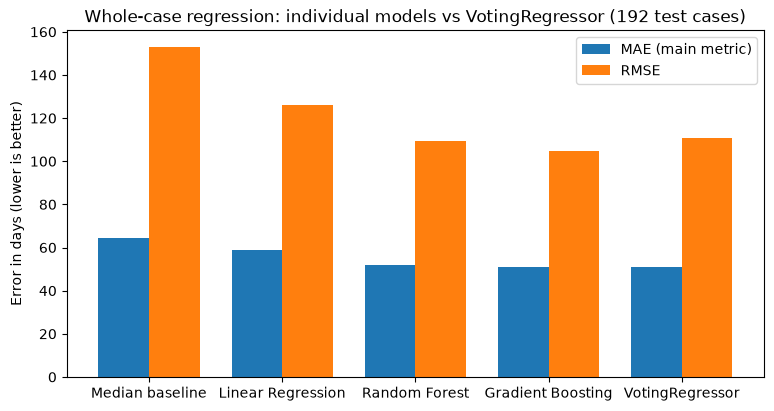

In [11]:
names = list(comparison.index)
positions = list(range(len(names)))
width = 0.38

plt.figure(figsize=(9, 4.5))
plt.bar([p - width / 2 for p in positions], comparison["MAE"], width, label="MAE (main metric)")
plt.bar([p + width / 2 for p in positions], comparison["RMSE"], width, label="RMSE")
plt.xticks(positions, names)
plt.ylabel("Error in days (lower is better)")
plt.title("Whole-case regression: individual models vs VotingRegressor (192 test cases)")
plt.legend()
plt.show()

## 11. Interpretation

**The original results are reproduced exactly** (MAE 64.42 / 59.01 / 52.00 / 51.19 days), and the voting prediction is
exactly the average of the three separate models.

**Did voting improve MAE?** Practically no. VotingRegressor has an MAE of 51.16 days, compared with 51.19 for Gradient
Boosting, the best single model: a difference of 0.03 days on 192 test cases, which is far too small to matter.

**RMSE and R² are worse.** VotingRegressor has an RMSE of 110.87 days and R² of 0.43, compared with 104.63 and 0.49 for
Gradient Boosting and 109.60 and 0.44 for Random Forest. The average includes Linear Regression, whose errors on the
longest cases are much larger (RMSE 126.02), so averaging it in increases the large errors that RMSE penalises.

**One small benefit:** none of the voting predictions is below zero (lowest 27.96 days), while Linear Regression alone
predicts 4 impossible negative values (lowest −14.39 days).

**Answer.** An ensemble does not automatically improve predictions. Here, combining the three models with equal weights
gives about the same MAE as Gradient Boosting alone and worse RMSE and R². This is still a **whole-case** regression
exercise: the features are only known after a case ends, so none of these models can be used for early warning.

## 12. Limitations

- The features describe the **whole finished case**, so none of these models can give an early warning.
- The target is the **recorded activity span**, not a legal deadline, a verified completion time or a delay.
- The 192 test cases were **already used** in notebooks 02–05; this is one random split, so small differences are uncertain.
- No settings or voting weights were tuned; other weights could give other results.
- Regression MAE (in days) cannot be compared with the ROC-AUC of the day-30 classification notebooks: they measure
  different things for different problems.
- Model results are not causal explanations. One Dutch municipality; not SPAR or Montenegro data.